# 09 · Analysis

The five research questions from the PRD, answered with the 297 runs on Claude Haiku 5.5.

**Scores:** T1 and T2 runs score 1 (right) or 0 (wrong), so a mean is the share answered correctly.
T3 runs score the F1 of the predicted pair list. With 6 questions per cell (2 at 2M), one question moves a cell by 17 points:
read differences of a few points as noise.

In [1]:
import json, sys
from pathlib import Path

import pandas as pd

ROOT = Path("..")
sys.path.append(str(ROOT / "scripts"))
METHODS = ["rag_bm25", "rag_hybrid", "direct_llm", "rlm_depth0", "rlm_depth1", "rlm_depth2"]
SIZES = ["32k", "128k", "512k", "2m"]
runs = pd.concat(pd.read_json(p, lines=True) for p in (ROOT / "results/runs").glob("*.jsonl"))
runs["size"] = pd.Categorical(runs["size"], SIZES, ordered=True)
runs["method"] = pd.Categorical(runs["method"], METHODS, ordered=True)
qs = pd.read_json(ROOT / "data/processed/questions.jsonl", lines=True)
print(f"{len(runs)} runs, {runs.method.nunique()} methods, {runs.id.nunique()} questions")

import matplotlib.pyplot as plt

FIG = ROOT / "report/figures"
FIG.mkdir(parents=True, exist_ok=True)
# Categorical slots 1-6 of the validated reference palette, fixed per method; markers are the second encoding.
STYLE = {"rag_bm25": ("#2a78d6", "o"), "rag_hybrid": ("#eb6834", "s"), "direct_llm": ("#1baf7a", "^"),
         "rlm_depth0": ("#eda100", "D"), "rlm_depth1": ("#e87ba4", "v"), "rlm_depth2": ("#008300", "P")}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})

297 runs, 6 methods, 59 questions


## Metrics table
One row per method × size × tier: mean score, cost, latency and RLM effort. Saved as `results/metrics.csv`.

In [2]:
metrics = (runs.groupby(["method", "size", "tier"], observed=True)
           .agg(runs=("score", "size"), score=("score", "mean"), cost_mean=("cost", "mean"), cost_median=("cost", "median"),
                seconds_median=("seconds", "median"), input_tokens=("input_tokens", "mean"),
                sub_calls=("sub_calls", "mean"), steps=("steps", "mean"))
           .round(4).reset_index())
metrics.to_csv(ROOT / "results/metrics.csv", index=False)
runs.pivot_table(index="method", columns="tier", values="score", aggfunc="mean", observed=True).round(2)

tier,T1,T2,T3
method,,,
rag_bm25,0.90,0.00,0.07
rag_hybrid,0.70,0.10,0.06
direct_llm,0.85,0.15,0.34
rlm_depth0,0.85,0.45,0.80
rlm_depth1,0.85,0.60,0.84
rlm_depth2,NaN,0.67,0.89


## RQ1 · How does accuracy change as the context grows?
*Hypothesis: direct LLM degrades fast; RLM degrades slowest.*

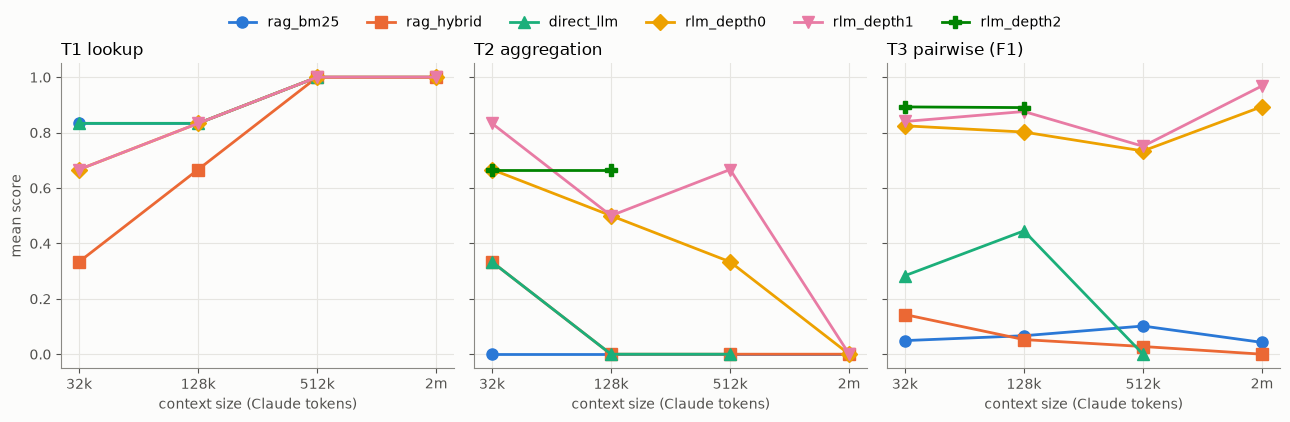

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, tier, title in zip(axes, ["T1", "T2", "T3"], ["T1 lookup", "T2 aggregation", "T3 pairwise (F1)"]):
    cell = runs[runs.tier == tier].pivot_table(index="size", columns="method", values="score", aggfunc="mean", observed=False)
    for m in METHODS:
        if m in cell and cell[m].notna().any():
            color, marker = STYLE[m]
            ax.plot(range(len(SIZES)), cell[m].reindex(SIZES).values, color=color, marker=marker, lw=2, ms=8, label=m)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xticks(range(len(SIZES)), SIZES)
    ax.set_xlabel("context size (Claude tokens)")
    ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel("mean score")
fig.legend(*axes[2].get_legend_handles_labels(), loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
fig.savefig(FIG / "accuracy_vs_size.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
# the same numbers as a table (T2 + T3: the questions that need every record)
runs[runs.tier != "T1"].pivot_table(index="method", columns="size", values="score", aggfunc="mean", observed=False).round(2)

size,32k,128k,512k,2m
method,,,,
rag_bm25,0.02,0.03,0.05,0.02
rag_hybrid,0.25,0.03,0.01,0.00
direct_llm,0.31,0.22,0.00,NaN
rlm_depth0,0.74,0.65,0.53,0.45
rlm_depth1,0.84,0.69,0.71,0.48
rlm_depth2,0.77,0.78,NaN,NaN


## RQ2 · Does the answer depend on question type?
*Hypothesis: RAG ≈ RLM on lookups; RLM wins aggregation; only RLM survives pairwise.*

In [5]:
runs.pivot_table(index="tier", columns="method", values="score", aggfunc="mean", observed=True).round(2)

method,rag_bm25,rag_hybrid,direct_llm,rlm_depth0,rlm_depth1,rlm_depth2
tier,,,,,,
T1,0.90,0.70,0.85,0.85,0.85,NaN
T2,0.00,0.10,0.15,0.45,0.60,0.67
T3,0.07,0.06,0.34,0.80,0.84,0.89


## RQ3 · Does recursion matter, or is the REPL alone enough?
*Hypothesis: depth 0 handles lookups; depth 1+ is needed for aggregation and pairwise.*
Depth 2 only ran on T2/T3 at 32K and 128K, so the fair comparison is on exactly those questions.

In [6]:
same = runs[runs.method.isin(["rlm_depth0", "rlm_depth1", "rlm_depth2"]) & runs.id.isin(runs[runs.method == "rlm_depth2"].id)]
(same.groupby("method", observed=True)
     .agg(score=("score", "mean"), cost_median=("cost", "median"), cost_max=("cost", "max"),
          seconds_median=("seconds", "median"), sub_calls=("sub_calls", "mean"))
     .round(4))

,score,cost_median,cost_max,seconds_median,sub_calls
method,,,,,
rlm_depth0,0.6928,0.0046,0.0095,27.7,0.0000
rlm_depth1,0.7590,0.0055,0.0262,35.2,3.8696
rlm_depth2,0.7741,0.0586,0.4409,470.1,20.6957


## RQ4 · What do the methods cost?
*Hypothesis: RLM median cost is close to RAG, with much higher variance.*

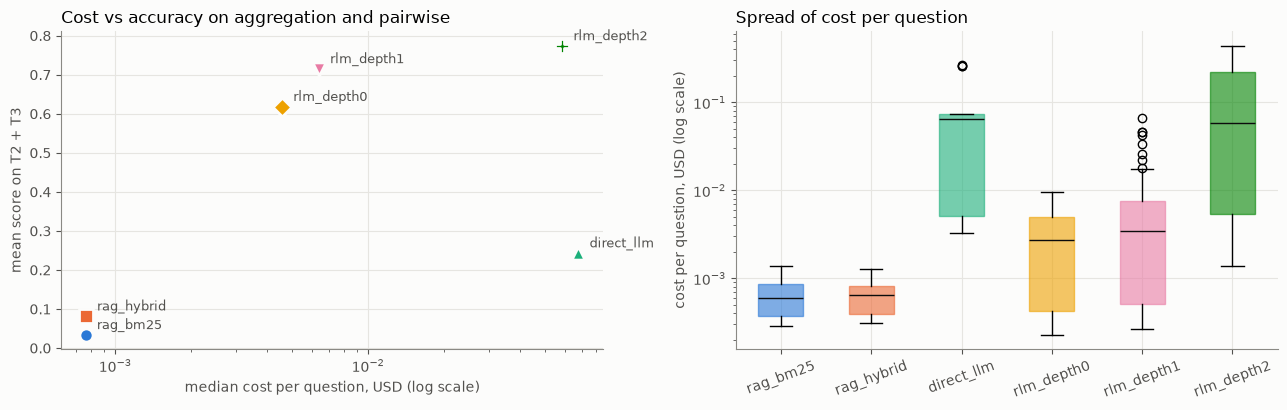

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2))
hard = runs[runs.tier != "T1"]
for m in METHODS:
    color, marker = STYLE[m]
    r = hard[hard.method == m]
    a.scatter(r.cost.median(), r.score.mean(), s=90, color=color, marker=marker, edgecolor="#fcfcfb", lw=2, zorder=3)
    a.annotate(m, (r.cost.median(), r.score.mean()), textcoords="offset points", xytext=(8, 4), fontsize=9, color="#52514e")
a.set_xscale("log")
a.set_xlabel("median cost per question, USD (log scale)")
a.set_ylabel("mean score on T2 + T3")
a.set_title("Cost vs accuracy on aggregation and pairwise", loc="left", fontsize=12)
data = [runs[runs.method == m].cost.clip(lower=1e-5) for m in METHODS]
box = b.boxplot(data, orientation="vertical", patch_artist=True, widths=0.5, medianprops={"color": "#0b0b0b"})
for patch, m in zip(box["boxes"], METHODS):
    patch.set(facecolor=STYLE[m][0], alpha=0.6, edgecolor=STYLE[m][0])
b.set_xticks(range(1, len(METHODS) + 1), METHODS, rotation=20)
b.set_yscale("log")
b.set_ylabel("cost per question, USD (log scale)")
b.set_title("Spread of cost per question", loc="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "cost_vs_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
runs.groupby("method", observed=True).cost.describe(percentiles=[0.5, 0.9])[["count", "50%", "90%", "max"]].round(4)

,count,50%,90%,max
method,,,,
rag_bm25,59.0,0.0006,0.0010,0.0014
rag_hybrid,59.0,0.0006,0.0010,0.0013
direct_llm,38.0,0.0646,0.0742,0.2662
rlm_depth0,59.0,0.0027,0.0071,0.0095
rlm_depth1,59.0,0.0034,0.0229,0.0659
rlm_depth2,23.0,0.0586,0.3935,0.4409


## RQ5 · How do RLMs fail?
*Hypothesis: bad first decomposition, code errors, runaway sub-calls.*

Every RLM run that was not fully correct is put in **one** category, checked in this order:
1. **gave up / out of turns**: no answer, or the model said it could not finish
2. **runaway sub-calls**: 30+ sub-calls or ≥ $0.10 for one question
3. **code errors**: 3+ tracebacks in the REPL output
4. **near miss**: T2 answer within 5 points, or T3 F1 ≥ 0.7 (mostly label disagreements with the answer key)
5. **wrong answer**: anything else

In [9]:
def trace(r):
    p = ROOT / "results/runs/trajectories" / r.method / f"{r.id}.json"
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else []

def category(r):
    answer = r.reply.removeprefix("ANSWER:").strip()
    errors = sum(o.count("Traceback") for step in trace(r) for o in step["outputs"])
    if not answer or "unable" in answer.lower():
        return "gave up / out of turns"
    if r.sub_calls >= 30 or r.cost >= 0.10:
        return "runaway sub-calls"
    if errors >= 3:
        return "code errors"
    truth = qs.set_index("id").answer[r.id]
    if r.tier == "T2":
        try:
            if abs(float(answer.split()[0].rstrip("%")) - truth) <= 5:
                return "near miss"
        except ValueError:
            pass
    if r.tier == "T3" and r.score >= 0.7:
        return "near miss"
    return "wrong answer"

rlm = runs[runs.method.astype(str).str.startswith("rlm") & (runs.score < 1)].copy()
rlm["failure"] = rlm.apply(category, axis=1)
rlm.pivot_table(index="failure", columns="method", values="id", aggfunc="count", fill_value=0, observed=True)

method,rlm_depth0,rlm_depth1,rlm_depth2
failure,,,
code errors,1,1,0
gave up / out of turns,0,1,0
near miss,12,15,6
runaway sub-calls,0,0,6
wrong answer,16,9,0


In [10]:
for cat, r in rlm.groupby("failure"):
    ex = r.iloc[0]
    print(f"--- {cat}: {ex.method} {ex.id} (score {ex.score:.2f}, {ex.sub_calls:.0f} sub-calls, ${ex.cost:.3f})")
    print("   ", ex.reply[:200].replace(chr(10), " "), "\n")

--- code errors: rlm_depth0 128k-T2-1 (score 0.00, 0 sub-calls, $0.010)
    ANSWER: 6.4 

--- gave up / out of turns: rlm_depth1 512k-T2-1 (score 0.00, 24 sub-calls, $0.046)
    ANSWER: Unable to determine: the classification covered only 1,900 of the 3,895 on-time or early orders, and no product-complaint count was computed. 

--- near miss: rlm_depth0 32k-T2-3 (score 0.00, 0 sub-calls, $0.004)
    ANSWER: 72.0 

--- runaway sub-calls: rlm_depth2 32k-T2-1 (score 0.00, 60 sub-calls, $0.347)
    ANSWER: 6.3 

--- wrong answer: rlm_depth0 32k-T1-1 (score 0.00, 0 sub-calls, $0.001)
    ANSWER: product 



## Verdicts

| RQ | Hypothesis | Verdict | Evidence (mean scores; T2+T3 unless stated) |
|---|---|---|---|
| RQ1 | Direct LLM degrades fast; RLM slowest | **Supported** | Direct 0.31 → 0.22 → 0.00 (32K → 512K), cannot run at 2M. RLM depth 1: 0.84 → 0.69 → 0.71 → 0.48. RAG is near 0 at every size. |
| RQ2 | RAG ≈ RLM on lookups; RLM wins aggregation; only RLM survives pairwise | **Supported** | T1: RAG-BM25 0.90, RLM 0.85, direct 0.85. T2: RLM 0.45-0.67 vs RAG ≤ 0.10, direct 0.15. T3: RLM 0.80-0.89 vs RAG ≤ 0.07; direct reaches 0.34 at small sizes but 0 at 512K. |
| RQ3 | Depth 0 for lookups; depth 1+ needed for aggregation/pairwise | **Partly** | The REPL alone already does most of the work (depth 0: T3 0.80). Depth 1 helps aggregation (T2 0.45 → 0.60). Depth 2 adds almost nothing on the same questions (0.77 vs 0.76) at ~10× the median cost and ~13× the time. |
| RQ4 | RLM median cost close to RAG, much higher variance | **Supported** | Median $/question: RAG 0.0006, RLM depth 1 0.0034, direct 0.065. RLM depth 1's 90th percentile is ~7× its median; depth 2 reached $0.44 on one question. |
| RQ5 | Bad decomposition, code errors, runaway sub-calls | **Partly** | Most imperfect RLM runs are near misses (labels that differ slightly from the answer key), then plainly wrong answers. Runaway sub-calls appear only at depth 2; code errors are rare; one run ran out of turns after choosing too-small batches. |

**Where every method failed:** both T2 questions at 2M (2,800 and 15,300 matching orders). That is more reading than an RLM can do
within 12 turns and 60 sub-calls; RLM needs either bigger batches or higher caps at that scale.

**Limitations.** One model (Claude Haiku 5.5) and one run per question; 6 questions per cell (2 at 2M), so small differences are noise.
The answer key is LLM-made and checked against a 200-review human audit (93.0% agreement after the labeling rules were sharpened;
19 audit labels were edited by those rules). The data is e-commerce last-mile delivery, not freight logistics.